In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('hour.csv')

print("Shape:", df.shape)

df.head()

Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [3]:
df.describe().round(2)

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.00,17379.00,17379.0,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,8690.00,2.50,0.5,6.54,11.55,0.03,3.00,0.68,1.43,0.50,0.48,0.63,0.19,35.68,153.79,189.46
std,5017.03,1.11,0.5,3.44,6.91,0.17,2.01,0.47,0.64,0.19,0.17,0.19,0.12,49.31,151.36,181.39
min,1.00,1.00,0.0,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00
25%,4345.50,2.00,0.0,4.00,6.00,0.00,1.00,0.00,1.00,0.34,0.33,0.48,0.10,4.00,34.00,40.00
50%,8690.00,3.00,1.0,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.63,0.19,17.00,115.00,142.00
75%,13034.50,3.00,1.0,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.78,0.25,48.00,220.00,281.00
max,17379.00,4.00,1.0,12.00,23.00,1.00,6.00,1.00,4.00,1.00,1.00,1.00,0.85,367.00,886.00,977.00


In [4]:
(df['casual'] + df['registered'] == df['cnt']).all()

np.True_

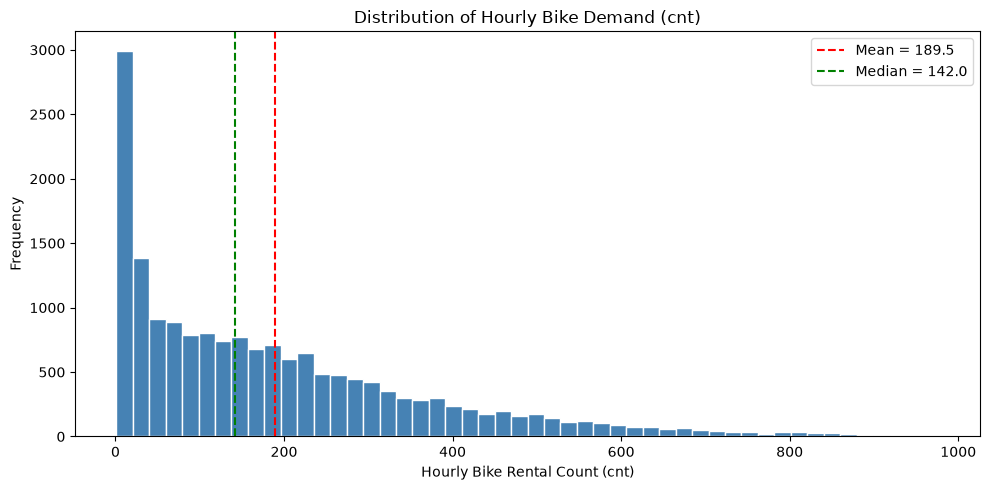

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['cnt'], bins=50, color='steelblue', edgecolor='white')
plt.xlabel('Hourly Bike Rental Count (cnt)')
plt.ylabel('Frequency')
plt.title('Distribution of Hourly Bike Demand (cnt)')
plt.axvline(df['cnt'].mean(), color='red', linestyle='--', label=f'Mean = {df["cnt"].mean():.1f}')
plt.axvline(df['cnt'].median(), color='green', linestyle='--', label=f'Median = {df["cnt"].median():.1f}')
plt.legend()
plt.tight_layout()
plt.show()

**Observation**: The distribution of `cnt` is **right-skewed** — the mean (189.5) is notably higher than the median (142.0), and the right tail extends to 977. This suggests that most hours have moderate demand, but a few peak hours (likely rush hours or special events) push the average up.

**Implication**: Tree-based models (Random Forest, XGBoost) do not require transformation of the target variable. However, we note this skew for interpretation and consider it when evaluating model residuals.

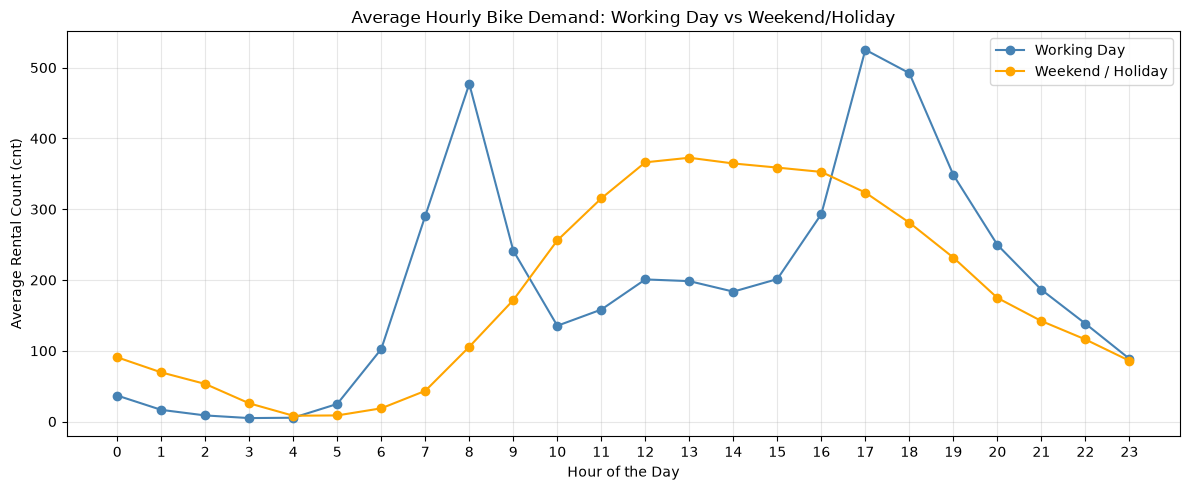

In [7]:
import matplotlib.pyplot as plt

hourly_avg = df.groupby(['workingday', 'hr'])['cnt'].mean().reset_index()

workday = hourly_avg[hourly_avg['workingday'] == 1]
weekend = hourly_avg[hourly_avg['workingday'] == 0]

plt.figure(figsize=(12, 5))
plt.plot(workday['hr'], workday['cnt'], marker='o', label='Working Day', color='steelblue')
plt.plot(weekend['hr'], weekend['cnt'], marker='o', label='Weekend / Holiday', color='orange')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Rental Count (cnt)')
plt.title('Average Hourly Bike Demand: Working Day vs Weekend/Holiday')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation**: The hourly demand pattern differs sharply between working days and weekends/holidays.

- **Working days**: Two distinct peaks — a morning rush around **8 AM** and an evening rush around **5–6 PM**. Demand dips significantly during the late morning and early afternoon.
- **Weekends / holidays**: A single broad peak from **late morning to late afternoon**, with no sharp commuter spikes.

**Implication**: This strongly suggests that the underlying demand is driven by two different behaviors: **commuting** on working days and **leisure** on weekends/holidays. A single global model may struggle to fit both patterns simultaneously, motivating our decision to treat `hr` as a categorical feature and to consider the interaction between `hr` and `workingday`.

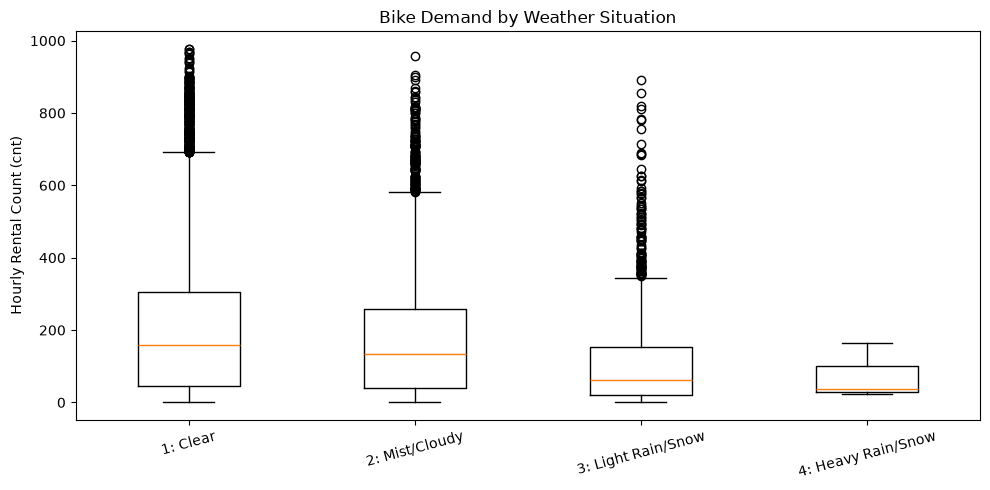

In [9]:
import matplotlib.pyplot as plt

weather_labels = {1: '1: Clear', 2: '2: Mist/Cloudy', 3: '3: Light Rain/Snow', 4: '4: Heavy Rain/Snow'}

plt.figure(figsize=(10, 5))
data_to_plot = [df[df['weathersit'] == w]['cnt'].values for w in [1, 2, 3, 4]]

plt.boxplot(data_to_plot, tick_labels=[weather_labels[w] for w in [1, 2, 3, 4]])

plt.ylabel('Hourly Rental Count (cnt)')
plt.title('Bike Demand by Weather Situation')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

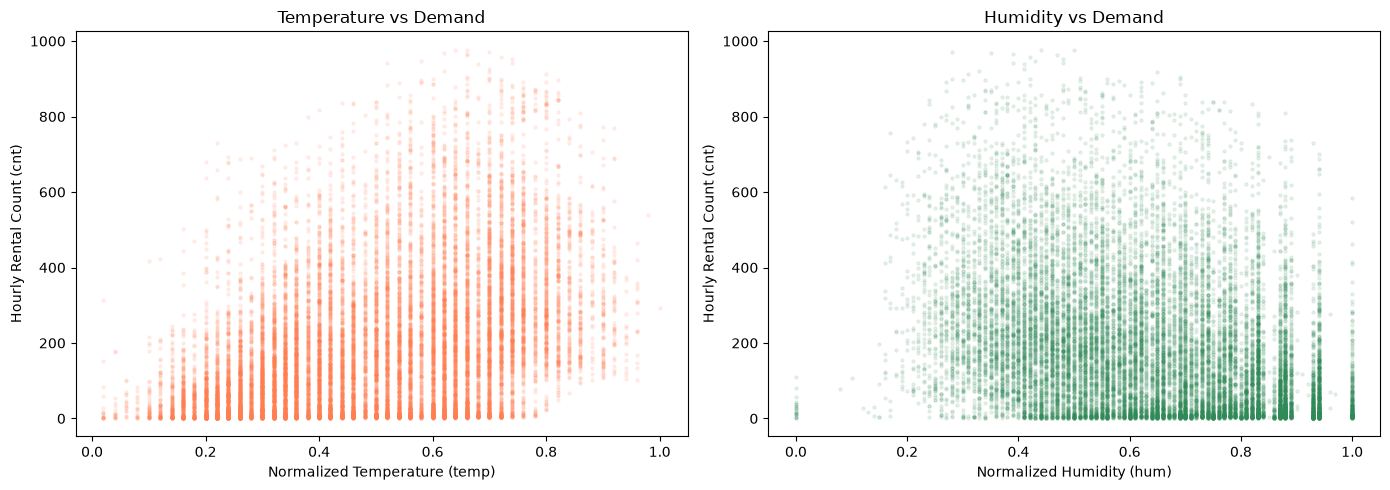

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['temp'], df['cnt'], alpha=0.1, s=5, color='coral')
axes[0].set_xlabel('Normalized Temperature (temp)')
axes[0].set_ylabel('Hourly Rental Count (cnt)')
axes[0].set_title('Temperature vs Demand')

axes[1].scatter(df['hum'], df['cnt'], alpha=0.1, s=5, color='seagreen')
axes[1].set_xlabel('Normalized Humidity (hum)')
axes[1].set_ylabel('Hourly Rental Count (cnt)')
axes[1].set_title('Humidity vs Demand')

plt.tight_layout()
plt.show()

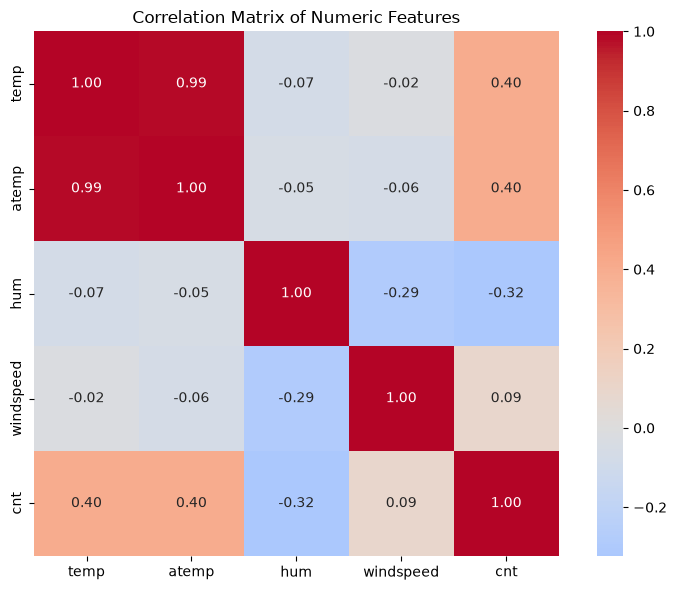

In [11]:
import seaborn as sns

numeric_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

**Observation**: Weather strongly influences bike demand.

1. **Weather situation (`weathersit`)**: Demand drops monotonically as conditions worsen. Clear days show the highest median; light rain/snow roughly halves the median; heavy rain/snow has very few observations (only 3 rows in the dataset), so its estimate is unreliable.
2. **Temperature (`temp`)**: Moderate positive correlation with `cnt` (r ≈ 0.40). Warmer hours see higher demand.
3. **Humidity (`hum`)**: Moderate negative correlation (r ≈ −0.32). Muggy hours see lower demand.
4. **`temp` vs `atemp`**: These two are near-perfectly correlated (r > 0.98), so we will **drop `atemp`** to avoid multicollinearity. Tree models are robust to it, but removing one keeps the feature importance analysis cleaner.
5. **`windspeed`**: Almost uncorrelated with demand, so it may contribute little — but we will keep it and let the model decide.

**Implication**: Weather is a meaningful secondary driver. We keep `weathersit`, `temp`, and `hum` as features. We explicitly exclude `atemp` because of collinearity with `temp`.

In [12]:
for w in [1, 2, 3, 4]:
    n = (df['weathersit'] == w).sum()
    print(f"weathersit={w}: count={n}, median cnt={df[df['weathersit'] == w]['cnt'].median():.1f}")

weathersit=1: count=11413, median cnt=159.0
weathersit=2: count=4544, median cnt=133.0
weathersit=3: count=1419, median cnt=63.0
weathersit=4: count=3, median cnt=36.0


In my analysis, clear weather yields a median demand of 159 rentals per hour, while light rain/snow cuts it down to 63 — a drop of roughly 60%. Heavy rain/snow is extremely rare in the dataset (only 3 records), so its estimate is unreliable and we should not over-interpret it.

**Observation**: Weather strongly influences bike demand.

- Clear weather yields a median demand of 159, while light rain/snow cuts it to 63 (a ~60% drop).

- temp shows a moderate positive correlation with cnt (r ≈ 0.40).

- hum shows a moderate negative correlation (r ≈ -0.32).

- Crucially, temp and atemp are highly collinear (r = 0.99), so we will drop atemp to avoid redundancy.

In [13]:
df_prep = df.copy()

cols_to_drop = ['casual', 'registered', 'atemp', 'instant', 'dteday']

df_prep = df_prep.drop(columns=cols_to_drop)

print("Remaining columns:", df_prep.columns.tolist())

Remaining columns: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']


In [14]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df_prep, test_size=0.2, random_state=42)

df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f"Train size: {len(df_train)}")
print(f"Val size:   {len(df_val)}")
print(f"Test size:  {len(df_test)}")

Train size: 10427
Val size:   3476
Test size:  3476


In [15]:
y_train = df_train['cnt'].values
y_val = df_val['cnt'].values
y_test = df_test['cnt'].values

del df_train['cnt']
del df_val['cnt']
del df_test['cnt']

print("Features after dropping target:", df_train.columns.tolist())
print("Shape of X_train:", df_train.shape)
print("Shape of y_train:", y_train.shape)

Features after dropping target: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']
Shape of X_train: (10427, 11)
Shape of y_train: (10427,)


In [16]:
import numpy as np

def build_features(df, hr_version='v1'):
    """
    根据不同的 hr 版本，把 DataFrame 转成字典列表。
    v1: 原始数值 (0-23)
    v2: 字符串类别 (用于 One-hot)
    v3: 循环编码 (sin/cos)
    """
    features = df.copy()
    
    if hr_version == 'v1':
        pass
    elif hr_version == 'v2':
        features['hr'] = features['hr'].astype(str)
    elif hr_version == 'v3':
        features['hr_sin'] = np.sin(2 * np.pi * features['hr'] / 24)
        features['hr_cos'] = np.cos(2 * np.pi * features['hr'] / 24)
        features = features.drop(columns=['hr'])
        
    cat_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
    for col in cat_cols:
        features[col] = features[col].astype(str)
        
    return features.to_dict(orient='records')

In [17]:
import xgboost as xgb
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_squared_error

results = {}

for version in ['v1', 'v2', 'v3']:
    print(f"Training model with {version} encoding...")

    train_dicts = build_features(df_train, version)
    val_dicts = build_features(df_val, version)

    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)
    
    dtrain = xgb.DMatrix(X_train, label=y_train)
    dval = xgb.DMatrix(X_val, label=y_val)
    
    xgb_params = {
        'eta': 0.1,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror', 
        'nthread': 8,
        'seed': 42,
        'verbosity': 0,
    }
    
    model = xgb.train(xgb_params, dtrain, num_boost_round=100)
    
    y_pred = model.predict(dval)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    results[version] = rmse
    print(f"   -> RMSE: {rmse:.2f}\n")

print("=== Final Results ===")
for v, rmse in results.items():
    print(f"{v}: {rmse:.2f}")

Training model with v1 encoding...
   -> RMSE: 42.94

Training model with v2 encoding...
   -> RMSE: 54.37

Training model with v3 encoding...
   -> RMSE: 42.39

=== Final Results ===
v1: 42.94
v2: 54.37
v3: 42.39


**Feature Engineering Experiment: How to encode `hr`?**

We compared three ways to encode the `hr` (hour of day) feature using XGBoost (fixed 100 rounds, max_depth=6):

| Encoding | Description | Validation RMSE |
| :--- | :--- | :--- |
| **v1: Raw Numerical** | Keep `hr` as 0-23 integers | 42.94 |
| **v2: One-Hot** | Treat `hr` as 24 distinct categories | 54.37 |
| **v3: Sin/Cos Cyclical** | Map `hr` to a 24-hour cycle using `sin(2πhr/24)` and `cos(2πhr/24)` | **42.39** |

**Surprising Finding**: One-hot encoding performed significantly *worse*. Why? Tree-based models can efficiently split continuous numerical features with simple threshold rules (e.g., `hr > 17`). When `hr` is one-hot encoded into 24 sparse columns, a tree with limited depth struggles to capture the global pattern and becomes fragmented. 

**Conclusion**: The **Sin/Cos cyclical encoding (v3)** is the winner. It preserves the cyclic nature of time (midnight is close to 1 AM) and allows the tree to split efficiently. We will proceed with v3 for the final model.

In [19]:
df_full = pd.concat([df_train, df_val], ignore_index=True)
y_full = np.concatenate([y_train, y_val])

full_dicts = build_features(df_full, hr_version='v3')
test_dicts = build_features(df_test, hr_version='v3')

dv_final = DictVectorizer(sparse=True)
X_full = dv_final.fit_transform(full_dicts)
X_test = dv_final.transform(test_dicts)

dfull = xgb.DMatrix(X_full, label=y_full)
dtest = xgb.DMatrix(X_test)

xgb_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'nthread': 8,
    'seed': 42,
    'verbosity': 0,
}
final_model = xgb.train(xgb_params, dfull, num_boost_round=150)

y_pred_test = final_model.predict(dtest)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"Final Test RMSE: {final_rmse:.2f}")

importance_dict = final_model.get_score(importance_type='gain') 
top_features = sorted(importance_dict.items(), key=lambda x: x[1], reverse=True)[:10]

print("\nTop 10 Most Important Features (by gain):")
for feat, score in top_features:
    print(f"{feat}: {score:.1f}")

Final Test RMSE: 39.81

Top 10 Most Important Features (by gain):
f3: 724396.7
f2: 650327.9
f36: 533995.1
f17: 497983.0
f34: 456261.2
f21: 269192.2
f20: 209185.0
f24: 180783.1
f6: 74701.3
f10: 69940.8


In [21]:
feature_names = list(dv_final.get_feature_names_out())

dfull = xgb.DMatrix(X_full, label=y_full, feature_names=feature_names)
dtest = xgb.DMatrix(X_test, feature_names=feature_names)

final_model = xgb.train(xgb_params, dfull, num_boost_round=150)

y_pred_test = final_model.predict(dtest)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"Final Test RMSE: {final_rmse:.2f}\n")

importance_dict = final_model.get_score(importance_type='gain')
top_features = sorted(importance_dict.items(), key=lambda x: x[1], reverse=True)[:10]

print("Top 10 Most Important Features (by gain):")
for feat, score in top_features:
    print(f"{feat}: {score:.1f}")

Final Test RMSE: 39.81

Top 10 Most Important Features (by gain):
hr_sin: 724396.7
hr_cos: 650327.9
yr=0: 533995.1
season=1: 497983.0
workingday=0: 456261.2
temp: 269192.2
season=4: 209185.0
weathersit=3: 180783.1
mnth=10: 74701.3
mnth=3: 69940.8


In [22]:
import pandas as pd
import numpy as np
import xgboost as xgb
import pickle
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

def load_and_preprocess_data(filepath='hour.csv'):
    """載入資料並刪除無用/洩漏特徵"""
    df = pd.read_csv(filepath)
    cols_to_drop = ['casual', 'registered', 'atemp', 'instant', 'dteday']
    df = df.drop(columns=cols_to_drop)
    return df

def build_features(df, version='v3'):
    """特徵工程：這裡我們直接使用表現最好的 v3 (Sin/Cos) 編碼"""
    features = df.copy()
    
    if version == 'v3':
        features['hr_sin'] = np.sin(2 * np.pi * features['hr'] / 24)
        features['hr_cos'] = np.cos(2 * np.pi * features['hr'] / 24)
        features = features.drop(columns=['hr'])
        
    cat_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
    for col in cat_cols:
        if col in features.columns:
            features[col] = features[col].astype(str)
            
    return features.to_dict(orient='records')

def train_model():
    print("Loading data...")
    df = load_and_preprocess_data('hour.csv')
    
    df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
    
    y_train = df_train['cnt'].values
    y_test = df_test['cnt'].values
    
    del df_train['cnt']
    del df_test['cnt']
    
    print("Building features (v3 encoding)...")
    train_dicts = build_features(df_train, version='v3')
    test_dicts = build_features(df_test, version='v3')
    
    print("Vectorizing...")
    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(train_dicts)
    X_test = dv.transform(test_dicts)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)
    
    print("Training XGBoost model...")
    xgb_params = {
        'eta': 0.1,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'nthread': 8,
        'seed': 42,
        'verbosity': 0,
    }
    
    model = xgb.train(xgb_params, dtrain, num_boost_round=150)
    
    y_pred = model.predict(dtest)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    print(f"Test RMSE: {rmse:.2f}")
    
    print("Saving model and vectorizer...")
    model.save_model('model.json')  
    with open('dv.pkl', 'wb') as f:
        pickle.dump(dv, f)          
    print("Done!")

if __name__ == '__main__':
    train_model()

Loading data...
Building features (v3 encoding)...
Vectorizing...
Training XGBoost model...
Test RMSE: 39.81
Saving model and vectorizer...
Done!
